# 02 — Features y prevención de fuga

Las features se construyen exclusivamente con datos disponibles antes de la predicción: SMILES y condiciones de fase móvil/flujo. Los parámetros aprendidos (imputación y escalado) viven dentro del pipeline de scikit-learn y se ajustan solo en cada pliegue de entrenamiento.

In [1]:
from pathlib import Path
import os
import sys
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from src.datos import load_snapshot
from src.pipeline import FEATURE_COLUMNS, RAW_FEATURE_COLUMNS, MoleculeConditionFeatures, valid_smiles_mask
from src.splits import create_or_load_holdout, stratified_compound_sample

frame, metadata = load_snapshot()
valid = valid_smiles_mask(frame)
all_data = frame.loc[valid & frame["inchikey"].notna()].reset_index(drop=True)
train, holdout, split_metadata = create_or_load_holdout(all_data, source_sha256=metadata["sha256"])
data, sample_metadata = stratified_compound_sample(train, max_compounds=12_000, random_state=42)
X_raw = data.loc[:, RAW_FEATURE_COLUMNS]
feature_builder = MoleculeConditionFeatures()
X_features = feature_builder.fit_transform(X_raw)
y = data["tiempo_retencion"].astype(float)
print(f"Split completo: train={len(train):,}, holdout={len(holdout):,}; muestra estratificada de desarrollo={sample_metadata['compounds']:,} compuestos / {len(data):,} filas")
print(f"{X_raw.shape[1]} entradas disponibles -> {X_features.shape[1]} features derivadas; la evidencia con target usa solo train-sample")
display(X_features.head())

Split completo: train=122,370, holdout=30,216; muestra estratificada de desarrollo=12,000 compuestos / 19,406 filas
4 entradas disponibles -> 16 features derivadas; la evidencia con target usa solo train-sample


,mol_weight,mol_logp,mol_tpsa,mol_h_donors,mol_h_acceptors,mol_rotatable_bonds,mol_ring_count,mol_aromatic_rings,mol_fraction_csp3,elu_a_h2o,elu_a_meoh,elu_a_acn,elu_b_h2o,elu_b_meoh,elu_b_acn,flow_ml_min
0,326.849,3.44870,41.90,0.0,4.0,4.0,2.0,1.0,0.466667,100.0,0.0,0.0,0.0,0.0,100.0,0.1
1,384.501,2.31784,57.69,0.0,4.0,3.0,4.0,2.0,0.380952,100.0,0.0,0.0,0.0,0.0,100.0,0.1
2,468.941,3.70590,88.77,0.0,6.0,8.0,4.0,3.0,0.333333,100.0,0.0,0.0,0.0,0.0,100.0,0.1
3,474.587,1.61090,113.42,1.0,8.0,7.0,4.0,3.0,0.500000,100.0,0.0,0.0,0.0,0.0,100.0,0.6
4,372.490,4.27580,50.80,1.0,5.0,5.0,4.0,2.0,0.450000,100.0,0.0,0.0,0.0,0.0,100.0,0.1


,spearman,no_faltantes_%
elu_a_acn,-0.000,100.000
elu_a_h2o,0.059,100.000
elu_a_meoh,-0.058,100.000
elu_b_acn,0.154,100.000
elu_b_h2o,0.067,100.000
elu_b_meoh,-0.153,99.681
flow_ml_min,-0.705,96.042
mol_aromatic_rings,0.497,100.000
mol_fraction_csp3,-0.229,100.000
mol_h_acceptors,0.040,100.000


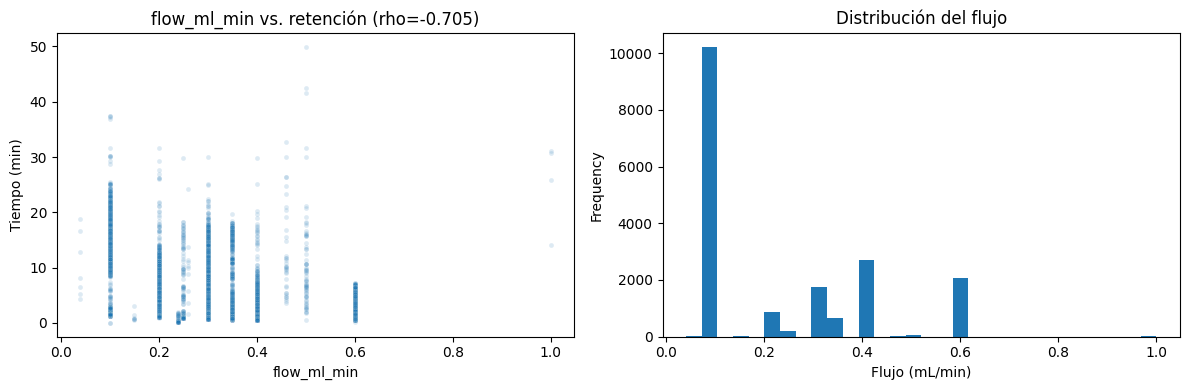

In [2]:
feature_evidence = X_features.assign(tiempo_retencion=y).corr(method="spearman")["tiempo_retencion"].drop("tiempo_retencion").dropna()
feature_evidence = feature_evidence.reindex(feature_evidence.abs().sort_values(ascending=False).index)
display(pd.DataFrame({"spearman": feature_evidence, "no_faltantes_%": 100 * X_features.notna().mean()} ).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
top = feature_evidence.index[0]
sns.scatterplot(x=X_features[top], y=y, alpha=0.15, s=12, ax=axes[0])
axes[0].set(title=f"{top} vs. retención (rho={feature_evidence[top]:.3f})", ylabel="Tiempo (min)")
X_features["flow_ml_min"].plot(kind="hist", bins=30, ax=axes[1], title="Distribución del flujo")
axes[1].set_xlabel("Flujo (mL/min)")
plt.tight_layout()
plt.show()

## Decisiones de diseño

| Feature derivada | Hallazgo de la EDA que la motiva | Evidencia de aporte | ¿Existe al inferir? | Codificación |
|---|---|---|---|---|
| Descriptores RDKit desde SMILES (peso, LogP, TPSA, donadores/aceptores, anillos, anillos aromáticos, fracción sp3, enlaces rotables) | Correlaciones y hallazgo 5 de 01: la retención depende de la molécula (LogP rho≈0,58, donadores rho≈−0,48) | Spearman de la tabla anterior y ablación por CV abajo | Sí: el químico conoce la estructura (SMILES) antes de inyectar | Numéricas: imputación por mediana + `StandardScaler` |
| Fracciones H2O/MeOH/ACN de las fases A y B, parseadas desde `fase_movil` | Hallazgo 3 de 01: las condiciones del método explican gran parte de la retención | Ablación: CV con y sin el bloque de método | Sí: la receta de fase móvil se define antes de la corrida | Numéricas. Se prefieren a un one-hot de las 12 recetas porque generalizan a recetas no vistas y conservan el orden de la composición |
| Flujo (mL/min) | Hallazgos 3 y 4: rho≈-0,72 y 4,35% de faltantes | Ablación + Spearman | Sí: parámetro operativo del método | Numérica: imputación por mediana dentro del pipeline |

**Variables categóricas.** `tipo_columna` (28 niveles, todos C18 por el filtro) **no** entra al modelo: el nombre comercial de la columna está muy concentrado (un solo nivel reúne más de la mitad de las filas), y una columna nueva del laboratorio sería un nivel no visto. Solo lo usa la línea base de negocio (mediana por condición). Si se agregara, se usaría `OneHotEncoder(handle_unknown="ignore", min_frequency=...)` dentro del `ColumnTransformer`. `fase_movil` se transforma en fracciones numéricas en lugar de codificarse como categoría.

**No se usan como predictores:** `tiempo_retencion` (target), `hecho_id`, `inchikey` (solo agrupa la CV) ni `nombre_compuesto`.

## Evidencia de aporte: ablación por bloques

Misma preparación (`src/pipeline.py`), mismo `GroupKFold` por InChIKey y misma métrica (RMSE) sobre la muestra de desarrollo. Se usa HistGradientBoosting por defecto. La última fila prueba `log(1+target)`, consecuencia del hallazgo 1. Es un análisis exploratorio de features y no se registra como candidato en MLflow.

,cv_rmse_mean,cv_rmse_std,cv_mae_mean,delta_vs_todas,supera_desviacion_pliegues
variante,,,,,
solo moleculares,3.778,0.306,2.670,1.174,True
moleculares + flujo,2.710,0.254,1.758,0.106,False
solo método (fase móvil + flujo),3.844,0.269,2.768,1.240,True
todas (configuración usada),2.604,0.240,1.693,0.000,False
todas + log(1+target),2.677,0.257,1.723,0.073,False


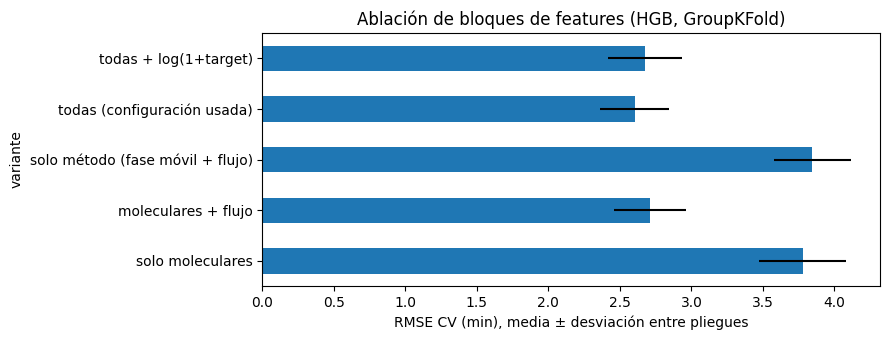

In [3]:
import numpy as np
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import cross_validate
from src.experiments import SCORING
from src.pipeline import MOLECULE_FEATURE_COLUMNS, make_group_cv, make_model_pipeline, model_inputs

X_dev, y_dev, groups_dev = model_inputs(data)
cv = make_group_cv(n_splits=5)
method_columns = [c for c in FEATURE_COLUMNS if c.startswith("elu_")]
variants = {
    "solo moleculares": make_model_pipeline(HistGradientBoostingRegressor(random_state=42), MOLECULE_FEATURE_COLUMNS),
    "moleculares + flujo": make_model_pipeline(HistGradientBoostingRegressor(random_state=42), [*MOLECULE_FEATURE_COLUMNS, "flow_ml_min"]),
    "solo método (fase móvil + flujo)": make_model_pipeline(HistGradientBoostingRegressor(random_state=42), [*method_columns, "flow_ml_min"]),
    "todas (configuración usada)": make_model_pipeline(HistGradientBoostingRegressor(random_state=42)),
    "todas + log(1+target)": TransformedTargetRegressor(
        regressor=make_model_pipeline(HistGradientBoostingRegressor(random_state=42)),
        func=np.log1p, inverse_func=np.expm1,
    ),
}
assert y_dev.min() >= 0, "log1p requiere retenciones no negativas"
ablation_rows = []
for name, estimator in variants.items():
    scores = cross_validate(estimator, X_dev, y_dev, groups=groups_dev, cv=cv, scoring=SCORING, n_jobs=1)
    ablation_rows.append({
        "variante": name,
        "cv_rmse_mean": -scores["test_rmse"].mean(),
        "cv_rmse_std": scores["test_rmse"].std(ddof=1),
        "cv_mae_mean": -scores["test_mae"].mean(),
    })
ablation = pd.DataFrame(ablation_rows).set_index("variante")
reference = ablation.loc["todas (configuración usada)"]
ablation["delta_vs_todas"] = ablation["cv_rmse_mean"] - reference["cv_rmse_mean"]
ablation["supera_desviacion_pliegues"] = ablation["delta_vs_todas"].abs() > reference["cv_rmse_std"]
display(ablation.round(3))

ax = ablation["cv_rmse_mean"].plot(kind="barh", xerr=ablation["cv_rmse_std"], figsize=(9, 3.5), color="tab:blue")
ax.set(xlabel="RMSE CV (min), media ± desviación entre pliegues", title="Ablación de bloques de features (HGB, GroupKFold)")
plt.tight_layout()
plt.show()

**Lectura de la ablación.** Un bloque aporta si quitarlo empeora el RMSE en más que la desviación entre pliegues (≈0,24 min):

- **Descriptores moleculares:** sin ellos (solo método) el RMSE sube de 2,60 a 3,84 min (+1,24). Aporte claro.
- **Condiciones del método:** sin ellas (solo moleculares) el RMSE sube a 3,78 min (+1,17). Aporte claro; casi todo viene del flujo (moleculares + flujo = 2,71).
- **Fracciones de fase móvil:** sobre moleculares + flujo mejoran 0,11 min, **menos que la desviación entre pliegues**: aporte no concluyente. Se conservan porque son baratas, no tienen fuga y describen el método para recetas nuevas.
- **log(1+target)** (consecuencia del hallazgo 1): empeora el RMSE en 0,07 min, así que se descarta y el modelo predice directamente en minutos.

La fila "todas" reproduce exactamente el RMSE CV del candidato HGB del notebook 03 (2,604), lo que confirma que ambos notebooks usan la misma preparación y los mismos pliegues.

## Prueba de ausencia de fuga

Cinco comprobaciones ejecutables. Si alguna falla, el notebook se detiene.

In [4]:
from sklearn.base import clone

checks = {}
# 1. Ninguna feature es el target ni un identificador.
forbidden = {"tiempo_retencion", "hecho_id", "inchikey", "nombre_compuesto"}
checks["sin_target_ni_ids_en_features"] = forbidden.isdisjoint(FEATURE_COLUMNS) and forbidden.isdisjoint(RAW_FEATURE_COLUMNS)

# 2. La transformación es fila a fila: el resultado de una fila no depende de las demás.
probe = X_raw.sample(200, random_state=42)
batch = MoleculeConditionFeatures().fit(probe).transform(probe)
row_by_row = pd.concat([MoleculeConditionFeatures().fit(probe.loc[[i]]).transform(probe.loc[[i]]) for i in probe.index])
checks["features_fila_a_fila"] = batch.equals(row_by_row)

# 3. El target no interviene: ajustar con y permutado produce las mismas features.
y_perm = y.sample(frac=1, random_state=0).to_numpy()
checks["features_independientes_de_y"] = (
    MoleculeConditionFeatures().fit(X_raw, y).transform(probe).equals(MoleculeConditionFeatures().fit(X_raw, y_perm).transform(probe))
)

# 4. Holdout y entrenamiento no comparten compuestos.
checks["holdout_sin_compuestos_de_train"] = set(train["inchikey"]).isdisjoint(holdout["inchikey"])

# 5. La imputación se aprende solo con el pliegue de entrenamiento.
X_dev_raw, y_dev_raw, groups_dev_raw = model_inputs(data)
fold_train, fold_valid = next(make_group_cv(n_splits=5).split(X_dev_raw, y_dev_raw, groups_dev_raw))
pipeline = clone(make_model_pipeline(HistGradientBoostingRegressor(random_state=42))).fit(X_dev_raw.iloc[fold_train], y_dev_raw.iloc[fold_train])
imputer = pipeline.named_steps["preprocessing"].named_transformers_["numeric"].named_steps["imputer"]
fold_medians = X_features.iloc[fold_train].median()
checks["imputacion_solo_con_train_fold"] = np.allclose(imputer.statistics_, fold_medians.loc[list(FEATURE_COLUMNS)].to_numpy())
checks["grupos_disjuntos_en_el_pliegue"] = set(groups_dev_raw.iloc[fold_train]).isdisjoint(groups_dev_raw.iloc[fold_valid])

display(pd.Series(checks, name="pasa").to_frame())
assert all(checks.values()), checks
print("Sin fuga: features fila a fila, sin target, compuestos disjuntos e imputación ajustada por pliegue.")

,pasa
sin_target_ni_ids_en_features,True
features_fila_a_fila,True
features_independientes_de_y,True
holdout_sin_compuestos_de_train,True
imputacion_solo_con_train_fold,True
grupos_disjuntos_en_el_pliegue,True


Sin fuga: features fila a fila, sin target, compuestos disjuntos e imputación ajustada por pliegue.
